# PDF file size and integrity analysis

This notebook reads the PDFs directly from `test-data/pdf`; it does not use the CSV size metadata. It checks whether each PDF opens and its pages load, reports files that are unreadable or repaired on open, and plots the number of files larger than each size threshold.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import pymupdf

pdf_dir_candidates = [
    Path('test-data/pdf'),
    Path('ibbi_gov_fetcher/test-data/pdf'),
    Path('legal/ibbi_gov_fetcher/test-data/pdf'),
]
pdf_dir = next((p.resolve() for p in pdf_dir_candidates if p.is_dir()), None)
if pdf_dir is None:
    raise FileNotFoundError('Could not find ibbi_gov_fetcher/test-data/pdf from the current working directory.')

pdf_paths = sorted(p for p in pdf_dir.rglob('*') if p.is_file() and p.suffix.lower() == '.pdf')
if not pdf_paths:
    raise FileNotFoundError(f'No PDF files found under {pdf_dir}')

records = []
for pdf_path in pdf_paths:
    size_bytes = pdf_path.stat().st_size  # Actual on-disk size, independent of CSV metadata.
    with pdf_path.open('rb') as f:
        has_pdf_header = f.read(5) == b'%PDF-'

    status, page_count, error = 'ok', 0, ''
    try:
        with pymupdf.open(pdf_path) as doc:
            if doc.needs_pass:
                status = 'encrypted_unchecked'
            else:
                page_count = len(doc)
                if page_count == 0:
                    status = 'zero_pages'
                else:
                    for page_number in range(page_count):
                        doc.load_page(page_number)
                    if doc.is_repaired:
                        status = 'repaired_on_open'
    except Exception as exc:
        status = 'unreadable'
        error = f'{type(exc).__name__}: {exc}'

    if not has_pdf_header and status == 'ok':
        status = 'missing_pdf_header'
    records.append({
        'file': str(pdf_path.relative_to(pdf_dir)),
        'size_bytes': size_bytes,
        'size_mb': size_bytes / 1_000_000,
        'pages': page_count,
        'integrity': status,
        'error': error,
    })

pdfs = pd.DataFrame(records)
print(f'PDF directory: {pdf_dir}')
print(f'Files scanned: {len(pdfs):,}')
print('Integrity results (encrypted PDFs are listed separately because their pages cannot be checked without a password):')
display(pdfs['integrity'].value_counts().rename('files').to_frame())
issues = pdfs.loc[pdfs['integrity'] != 'ok', ['file', 'size_bytes', 'pages', 'integrity', 'error']]
if issues.empty:
    print('No unreadable, repaired, empty, encrypted, or missing-header PDFs found.')
else:
    display(issues.sort_values(['integrity', 'file']).reset_index(drop=True))


PDF directory: E:\Docs\intern\AAintern\legal\ibbi_gov_fetcher\test-data\pdf
Files scanned: 1,091
Integrity results (encrypted PDFs are listed separately because their pages cannot be checked without a password):


,files
integrity,
ok,1091


No unreadable, repaired, empty, encrypted, or missing-header PDFs found.


## Number of PDFs larger than size x

For each observed file size threshold x, y is the number of PDF files whose actual on-disk size is strictly greater than x. The curve uses file sizes from every PDF found, including files flagged in the integrity check.

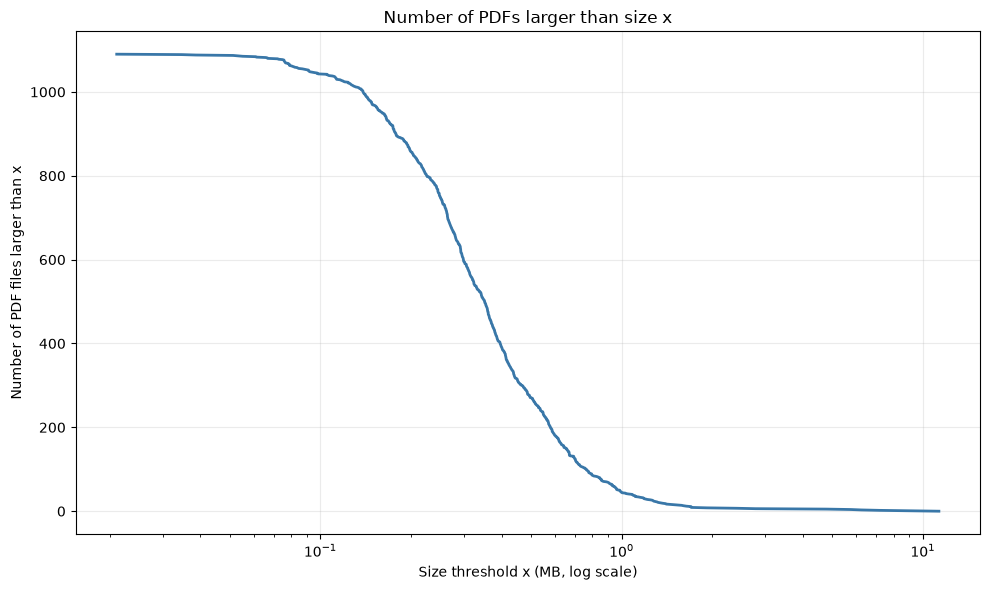

In [2]:
size_counts = pdfs['size_bytes'].value_counts().sort_index()
thresholds_mb = size_counts.index.to_numpy() / 1_000_000
documents_larger = (size_counts.iloc[::-1].cumsum().iloc[::-1] - size_counts).to_numpy()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(thresholds_mb, documents_larger, color='#3977a8', linewidth=2)
ax.set_xscale('log')
ax.set(
    title='Number of PDFs larger than size x',
    xlabel='Size threshold x (MB, log scale)',
    ylabel='Number of PDF files larger than x',
)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


## Select the 800 largest PDFs

The cutoff is chosen from the actual on-disk sizes so exactly 800 files have a size strictly greater than x.

In [3]:
TARGET_DOCUMENTS = 800
if len(pdfs) <= TARGET_DOCUMENTS:
    raise ValueError(f'Need more than {TARGET_DOCUMENTS} PDFs to define a strict size cutoff; found {len(pdfs)}.')

ranked = pdfs.sort_values(['size_bytes', 'file'], ascending=[True, True]).reset_index(drop=True)
cutoff_index = len(ranked) - TARGET_DOCUMENTS - 1
SIZE_THRESHOLD_BYTES = int(ranked.loc[cutoff_index, 'size_bytes'])
selected_pdfs = pdfs.loc[pdfs['size_bytes'] > SIZE_THRESHOLD_BYTES].copy()
if len(selected_pdfs) != TARGET_DOCUMENTS:
    raise ValueError(
        f'The size cutoff {SIZE_THRESHOLD_BYTES:,} bytes selects {len(selected_pdfs)} files, not {TARGET_DOCUMENTS}; '
        'there is a tie at the cutoff.'
    )
selected_pdfs = selected_pdfs.sort_values('size_bytes', ascending=False).reset_index(drop=True)
print(f'Threshold x: {SIZE_THRESHOLD_BYTES:,} bytes ({SIZE_THRESHOLD_BYTES / 1_000_000:.6f} MB)')
print(f'Files with size > x: {len(selected_pdfs):,}')
print(f'Files at or below x: {len(pdfs) - len(selected_pdfs):,}')


Threshold x: 225,512 bytes (0.225512 MB)
Files with size > x: 800
Files at or below x: 291


## Extract text from selected PDFs

This follows `00_ibbi_pdf_to_text.ipynb`: extract embedded text first, then OCR pages with fewer than 40 extracted characters. Both a page-marked TXT file and a JSON file with per-page extraction details are written for each selected PDF.

In [4]:
import json
import re
import shutil
import unicodedata
from pathlib import Path

import pytesseract
from PIL import Image

# Winget installs Tesseract here on Windows; use PATH when available.
tesseract_exe = shutil.which('tesseract') or r'C:\Program Files\Tesseract-OCR\tesseract.exe'
if not Path(tesseract_exe).is_file():
    raise FileNotFoundError('Tesseract executable not found; OCR cannot run.')
pytesseract.pytesseract.tesseract_cmd = tesseract_exe
print(f'Tesseract version: {pytesseract.get_tesseract_version()}')

OUTPUT_DIR = pdf_dir.parent / 'ibbi_text_output_800'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MIN_TEXT_CHARS = 40


def clean_page_text(text):
    text = unicodedata.normalize('NFKC', text or '')
    text = text.replace('\r\n', '\n').replace('\r', '\n').replace('\u00ad', '')
    lines = [re.sub(r'[ \t]+', ' ', line).strip() for line in text.split('\n')]
    return re.sub(r'\n{3,}', '\n\n', '\n'.join(lines)).strip()


def ocr_page(page):
    pixmap = page.get_pixmap(matrix=pymupdf.Matrix(2, 2), alpha=False)
    image = Image.frombytes('RGB', [pixmap.width, pixmap.height], pixmap.samples)
    return pytesseract.image_to_string(image, lang='eng')


def extract_pdf(pdf_path):
    relative_path = pdf_path.relative_to(pdf_dir)
    document_output_dir = OUTPUT_DIR / relative_path.parent
    document_output_dir.mkdir(parents=True, exist_ok=True)
    pages = []

    with pymupdf.open(pdf_path) as document:
        if document.needs_pass:
            raise PermissionError('PDF is password-protected; cannot extract its pages.')
        for page_number, page in enumerate(document, start=1):
            text = clean_page_text(page.get_text('text'))
            extraction_method = 'text'
            ocr_error = None
            if len(text) < MIN_TEXT_CHARS:
                try:
                    ocr_text = clean_page_text(ocr_page(page))
                    if len(ocr_text) > len(text):
                        text = ocr_text
                        extraction_method = 'ocr'
                except Exception as exc:
                    ocr_error = f'{type(exc).__name__}: {exc}'
            page_record = {
                'page': page_number,
                'text': text,
                'characters': len(text),
                'extraction_method': extraction_method,
            }
            if ocr_error:
                page_record['ocr_error'] = ocr_error
            pages.append(page_record)

    text_with_page_markers = '\n\n'.join(
        f"[PAGE {page['page']}]\n{page['text']}" for page in pages
    )
    result = {
        'source_file': pdf_path.name,
        'source_path': str(pdf_path),
        'source_size_bytes': pdf_path.stat().st_size,
        'page_count': len(pages),
        'total_characters': len(text_with_page_markers),
        'ocr_pages': sum(page['extraction_method'] == 'ocr' for page in pages),
        'ocr_errors': sum('ocr_error' in page for page in pages),
        'pages': pages,
        'text': text_with_page_markers,
    }
    txt_path = document_output_dir / f'{pdf_path.stem}.txt'
    json_path = document_output_dir / f'{pdf_path.stem}.json'
    txt_path.write_text(text_with_page_markers, encoding='utf-8')
    json_path.write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding='utf-8')
    return result, txt_path, json_path


manifest_rows = []
for index, row in selected_pdfs.iterrows():
    pdf_path = pdf_dir / row['file']
    try:
        result, txt_path, json_path = extract_pdf(pdf_path)
        manifest_rows.append({
            'source_file': row['file'],
            'size_bytes': int(row['size_bytes']),
            'status': 'extracted',
            'page_count': result['page_count'],
            'characters': result['total_characters'],
            'ocr_pages': result['ocr_pages'],
            'ocr_errors': result['ocr_errors'],
            'txt_path': str(txt_path),
            'json_path': str(json_path),
            'error': '',
        })
    except Exception as exc:
        manifest_rows.append({
            'source_file': row['file'],
            'size_bytes': int(row['size_bytes']),
            'status': 'failed',
            'page_count': 0,
            'characters': 0,
            'ocr_pages': 0,
            'ocr_errors': 0,
            'txt_path': '',
            'json_path': '',
            'error': f'{type(exc).__name__}: {exc}',
        })
    if (index + 1) % 25 == 0 or index + 1 == len(selected_pdfs):
        print(f'Processed {index + 1}/{len(selected_pdfs)} PDFs')

manifest = pd.DataFrame(manifest_rows)
manifest_path = OUTPUT_DIR / 'extraction_manifest.csv'
manifest.to_csv(manifest_path, index=False)
print(f'\nExtraction results: {manifest["status"].value_counts().to_dict()}')
print(f'Pages OCRed: {int(manifest["ocr_pages"].sum()):,}')
print(f'OCR errors: {int(manifest["ocr_errors"].sum()):,}')
print(f'Manifest: {manifest_path}')
display(manifest.loc[manifest['status'] != 'extracted'])


Tesseract version: 5.4.0.20240606


Processed 25/800 PDFs


Processed 50/800 PDFs


Processed 75/800 PDFs


Processed 100/800 PDFs


Processed 125/800 PDFs


... (24 outputs left out)

Processed 750/800 PDFs


Processed 775/800 PDFs


Processed 800/800 PDFs

Extraction results: {'extracted': 800}
Pages OCRed: 148
OCR errors: 0
Manifest: E:\Docs\intern\AAintern\legal\ibbi_gov_fetcher\test-data\ibbi_text_output_800\extraction_manifest.csv


,source_file,size_bytes,status,page_count,characters,ocr_pages,ocr_errors,txt_path,json_path,error


## Page counts for the selected PDFs

This cell summarizes the number of pages in the 800 successfully extracted PDFs and plots the document page-count distribution and page-count bands.

,pages per PDF
count,800.00
mean,21.13
std,19.33
min,1.00
25%,6.00
50%,18.00
75%,30.00
90%,41.00
95%,56.05
max,137.00


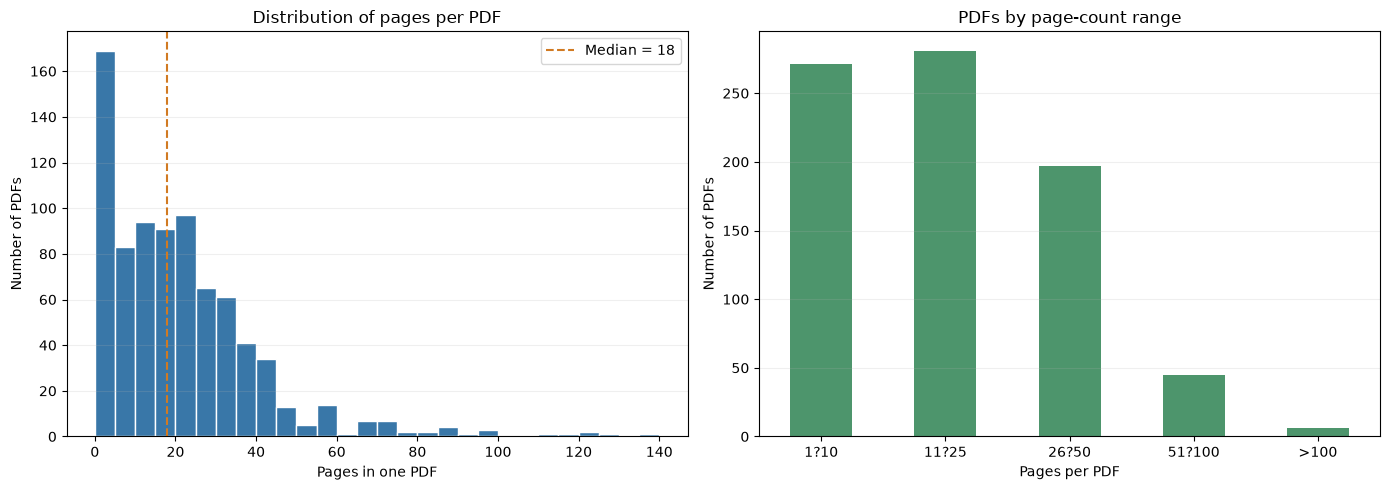

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

manifest_candidates = [
    Path('test-data/ibbi_text_output_800/extraction_manifest.csv'),
    Path('ibbi_gov_fetcher/test-data/ibbi_text_output_800/extraction_manifest.csv'),
    Path('legal/ibbi_gov_fetcher/test-data/ibbi_text_output_800/extraction_manifest.csv'),
]
manifest_path = next((p for p in manifest_candidates if p.is_file()), None)
if manifest_path is None:
    raise FileNotFoundError('Could not find the extraction_manifest.csv for the selected PDFs.')
page_manifest = pd.read_csv(manifest_path)
page_counts = pd.to_numeric(
    page_manifest.loc[page_manifest['status'].eq('extracted'), 'page_count'],
    errors='coerce',
).dropna()
if page_counts.empty:
    raise ValueError('No successfully extracted PDF page counts are available.')

page_summary = page_counts.describe(percentiles=[.25, .5, .75, .9, .95]).rename('pages per PDF').to_frame()
page_summary.loc['total pages'] = page_counts.sum()
display(page_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
hist_bins = np.arange(0, int(page_counts.max()) + 6, 5)
axes[0].hist(page_counts, bins=hist_bins, color='#3977a8', edgecolor='white')
axes[0].axvline(page_counts.median(), color='#d17a22', linestyle='--', label=f'Median = {page_counts.median():.0f}')
axes[0].set(title='Distribution of pages per PDF', xlabel='Pages in one PDF', ylabel='Number of PDFs')
axes[0].legend()
axes[0].grid(axis='y', alpha=.2)

page_bands = pd.cut(
    page_counts,
    bins=[0, 10, 25, 50, 100, float('inf')],
    labels=['1?10', '11?25', '26?50', '51?100', '>100'],
    right=True,
    include_lowest=True,
)
band_counts = page_bands.value_counts(sort=False)
band_counts.plot(kind='bar', ax=axes[1], color='#4d956c')
axes[1].set(title='PDFs by page-count range', xlabel='Pages per PDF', ylabel='Number of PDFs')
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y', alpha=.2)
plt.tight_layout()
plt.show()
